# Тихонов Илья

**Использование LLM:** решение (код и ответы) подготовлено с помощью OpenAI Codex и проверено и исправлено с помощью Claude Opus 5.5 (Anthropic).

# Домашнее задание 2. Линейная регрессия и градиентный спуск

## Математические методы анализа данных

В этом задании вы:

- **Обучите линейные модели** для предсказания цены подержанного автомобиля на данных из ДЗ-1: `LinearRegression`, `Lasso`, `ElasticNet`, `Ridge`, подберете гиперпараметры на кросс-валидации, примените one-hot-кодирование категорий;
- **Реализуете градиентный спуск** своими руками, посмотрите, как он ведёт себя на выпуклой и невыпуклой функции, и обучите с помощью него линейную регрессию.

**Дедлайн: 17 октября 2026, 23:59 (МСК).** Работы после дедлайна не принимаются.

**Максимальный балл за задание — 10.**

| Часть | Баллы |
|---|---|
| 0. Подготовка данных | 0 |
| 1. Линейная регрессия | 5 |
| 2. Градиентный спуск | 5 |
| **Итого** | **10** |

## <font color="red">Правила выполнения</font>

- Сдаём файл `.ipynb` через LMS. Перед сдачей перезапустите ноутбук и выполните все ячейки сверху вниз (*Kernel → Restart & Run All*, в Colab — *Среда выполнения → Перезапустить сеанс и выполнить все*). Ноутбук должен отработать без ошибок, все выводы и графики должны сохраниться.
- Если пользуетесь LLM или готовыми решениями из интернета, напишите об этом рядом с кодом: какая модель или какой ресурс. Решение нужно понимать полностью.
- После дедлайна 10–15 % работ случайно выбираются для онлайн-защиты: попросим объяснить решение. Если автор не может объяснить свой код, задание обнуляется.
- Оцениваются и код, и текстовые ответы. Если нет одного из двух, балл за пункт снижается.
- В каждом пункте сказано, на какой выборке работать: train или test. Всё, что «обучается» (scaler, кодировщик, модель), обучаем **только на train**, а к test только применяем.
- Ячейки с `assert` не меняйте: они проверяют, что у вас получились данные нужного размера или верные функции.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error

# Часть 0. Подготовка данных (0 баллов)

Работаем с теми же данными, что в ДЗ-1: объявления о продаже подержанных автомобилей в Индии. Целевая переменная (таргет) — `selling_price`, цена в рупиях.

| Признак | Что означает |
|---|---|
| `name` | марка и модель |
| `year` | год выпуска |
| `selling_price` | цена продажи в рупиях — **таргет** |
| `km_driven` | пробег, км |
| `fuel` | тип топлива |
| `seller_type` | кто продаёт: частное лицо или дилер |
| `transmission` | коробка передач |
| `owner` | какой по счёту владелец |
| `mileage` | сколько км машина проезжает на литре топлива (kmpl) или килограмме газа (km/kg) |
| `engine` | объём двигателя, см³ |
| `max_power` | мощность, л. с. (bhp) |
| `seats` | число мест |

Ниже — готовая предобработка по шагам ДЗ-1:
- убираем единицы измерения
- удаляем `torque`
- чиним `km_driven`
- заполняем пропуски медианами по train
- приводим `seats` к `int`
- удаляем дубли.

**Просто запустите ячейку.** Даже если в ДЗ-1 вы делали иначе, используйте этот код: тогда у всех одинаковые данные и ответы можно сверять.

In [3]:
URL = 'https://raw.githubusercontent.com/paiflare/ml_hse_2026/refs/heads/master/homework/hw_1/Data/'
df_train = pd.read_csv(URL + 'new_cars_train.csv')
df_test = pd.read_csv(URL + 'new_cars_test.csv')

for df in [df_train, df_test]:
    # '23.4 kmpl' -> 23.4, '1248 CC' -> 1248, '74 bhp' -> 74; если числа нет -> NaN
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = pd.to_numeric(df[col].str.split().str[0], errors='coerce')
    # torque удаляем, как в ДЗ-1
    df.drop(columns='torque', inplace=True)
    # в km_driven встречаются '-' и пропуски -> NaN
    df['km_driven'] = pd.to_numeric(df['km_driven'], errors='coerce')

# пропуски заполняем медианами, посчитанными только по train
cols_with_na = ['km_driven', 'mileage', 'engine', 'max_power', 'seats']
train_medians = df_train[cols_with_na].median()
df_train[cols_with_na] = df_train[cols_with_na].fillna(train_medians)
df_test[cols_with_na] = df_test[cols_with_na].fillna(train_medians)

df_train['seats'] = df_train['seats'].astype(int)
df_test['seats'] = df_test['seats'].astype(int)

# дубли по признакам (без таргета) удаляем только в train, оставляем первую строку
feature_cols = [col for col in df_train.columns if col != 'selling_price']
df_train = df_train.drop_duplicates(subset=feature_cols, keep='first').reset_index(drop=True)

print('train:', df_train.shape, ' test:', df_test.shape)

train: (5843, 12)  test: (1000, 12)


In [4]:
assert df_train.shape == (5843, 12) and df_test.shape == (1000, 12)
assert df_train.isna().sum().sum() == 0 and df_test.isna().sum().sum() == 0

df_train.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5
2,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5
3,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5
4,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000.0,Petrol,Individual,Manual,First Owner,20.14,1197.0,81.86,5


# Часть 1. Линейная регрессия (5 баллов)

Качество моделей оцениваем двумя метриками:

- **MSE** (среднеквадратичная ошибка, mean squared error): $$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2.$$ Чем меньше, тем лучше. Измеряется в «рупиях в квадрате».
- **$R^2$** (коэффициент детерминации): $$R^2 = 1 - \dfrac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2},$$ где $\bar y$ — среднее таргета **на той же выборке**, на которой считаем метрику. Показывает, какую долю разброса цен объясняет модель; $R^2 = 1$ — идеальные прогнозы.

**Здесь и далее для каждой обученной модели выводите $R^2$ и MSE на train и на test**, даже если в пункте об этом не сказано: иначе непонятно, стало ли лучше.

### Задание 1.1. Числовые признаки (0.25 балла)

Начнём с модели только на числовых признаках: `year`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`.

Запишите в `X_train` и `X_test` эти столбцы из `df_train` и `df_test`, а в `y_train` и `y_test` — таргет `selling_price` из тех же таблиц.

In [5]:
num_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

X_train = df_train[num_features]
y_train = df_train['selling_price']
X_test = df_test[num_features]
y_test = df_test['selling_price']

In [6]:
assert X_train.shape == (5843, 6) and X_test.shape == (1000, 6)
assert y_train.shape == (5843,) and y_test.shape == (1000,)

### Задание 1.2. Первая модель (0.5 балла)

1. **(0.15)** Напишите функцию `print_metrics(model, X_train, y_train, X_test, y_test)`: она получает уже обученную модель и печатает $R^2$ и MSE на train и на test. Дальше пользуйтесь ей для всех моделей.
2. **(0.15)** Обучите линейную регрессию `LinearRegression` с параметрами по умолчанию на train. Выведите метрики.
3. **(0.2)** Ответьте на вопросы:
   - Какую долю разброса цен на test объясняет модель?
   - Сравните train и test по $R^2$ и по MSE. Почему выводы по двум метрикам расходятся? Подсказка: сравните разброс цен `y_train.std()` и `y_test.std()`.
   - Посчитайте $\text{RMSE} = \sqrt{\text{MSE}}$ на test. Какова типичная ошибка прогноза в рупиях? Много это или мало по сравнению с медианной ценой на train?

In [7]:
def print_metrics(model, X_train, y_train, X_test, y_test):
    for name, features, target in [('train', X_train, y_train), ('test', X_test, y_test)]:
        pred = model.predict(features)
        print(f'{name}: R2 = {r2_score(target, pred):.4f}, MSE = {mean_squared_error(target, pred):.2f}')

In [8]:
lin_reg_base = LinearRegression().fit(X_train, y_train)
print_metrics(lin_reg_base, X_train, y_train, X_test, y_test)

train: R2 = 0.5921, MSE = 116851699646.60
test: R2 = 0.5940, MSE = 233395049519.10


In [9]:
test_rmse = np.sqrt(mean_squared_error(y_test, lin_reg_base.predict(X_test)))
print(f'RMSE на test: {test_rmse:.0f} руб.')
print(f'Медианная цена на train: {y_train.median():.0f} руб.')
print(f'Std цены: train = {y_train.std():.0f}, test = {y_test.std():.0f}')

RMSE на test: 483110 руб.
Медианная цена на train: 408000 руб.
Std цены: train = 535300, test = 758554


**Ваш ответ:**
- Модель объясняет около 59 % разброса цен на test: $R^2_{test} = 0.5940$
- По $R^2$ train и test почти одинаковы (0.5921 и 0.5940), а по MSE test примерно вдвое хуже. Выводы расходятся из-за разного разброса цен: $\text{std}(y_{test}) = 758\,554$ против $\text{std}(y_{train}) = 535\,300$. $R^2$ делит ошибку на дисперсию цен, а MSE нет, поэтому на более разбросанном test абсолютная ошибка больше при той же доле $R^2$
- $\text{RMSE}_{test} = 483\,110$ руб. Это больше медианной цены на train (408 000). Типичная ошибка прогноза превышает цену типичной машины: ошибка очень большая, модель только на числовых признаках получается грубой

### Задание 1.3. Может ли $R^2$ быть отрицательным? (0.25 балла)

Часто говорят, что $R^2$ лежит от 0 до 1. Для линейной регрессии это верно **на обучающей выборке**: там модель не хуже константы, равной среднему. На новых данных $R^2$ бывает и меньше нуля. Проверим.

1. **(0.1)** Сделайте «константную модель»: каждому объекту test предскажите одно и то же число — среднюю цену на train `y_train.mean()`. Посчитайте $R^2$ этой модели на test.
2. **(0.15)** Ответьте: почему получилось меньше нуля? Посмотрите на формулу $R^2$: с каким прогнозом на test сравнивается модель? Что в итоге означает $R^2 < 0$?

In [10]:
y_pred_constant = np.full(len(y_test), y_train.mean())
print('R2 константной модели на test:', r2_score(y_test, y_pred_constant))
print('Средняя цена на train:', y_train.mean(), ' Средняя цена на test:', y_test.mean())

R2 константной модели на test: -0.01567827112821063
Средняя цена на train: 522967.81310970394  Средняя цена на test: 617901.042


**Ваш ответ:** Да, $R^2$ может быть отрицательным. В его формуле модель сравнивается с прогнозом, который для всех объектов равен среднему значению по test. Мы же предсказываем среднее по train (522 968), которое отличается от среднего по test (617 901). Поэтому ошибка нашей модели больше и получается $R^2 \approx -0.0157$. Это означает, что модель предсказывает хуже, чем если бы мы всем объектам присвоили среднее по test

### Задание 1.4. Стандартизация и важность признаков (0.5 балла)

1. **(0.1)** Стандартизируйте признаки с помощью `StandardScaler`: обучите его (`fit`) **только на train**, затем преобразуйте (`transform`) и train, и test. Результаты запишите в `X_train_scaled` и `X_test_scaled`.
2. **(0.2)** Обучите `LinearRegression` на `X_train_scaled` и выведите метрики. Изменились ли они по сравнению с 1.2? Объясните почему.
3. **(0.2)** Выведите коэффициенты модели вместе с названиями признаков. Какой признак сильнее всего влияет на цену (по модулю коэффициента)? Почему сравнивать коэффициенты так можно только после стандартизации? Подсказка: сравните коэффициент при `km_driven` в моделях из 1.2 и 1.4.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
lin_reg_scaled = LinearRegression().fit(X_train_scaled, y_train)
print_metrics(lin_reg_scaled, X_train_scaled, y_train, X_test_scaled, y_test)

train: R2 = 0.5921, MSE = 116851699646.60
test: R2 = 0.5940, MSE = 233395049519.10


In [13]:
print('Коэффициенты линейной регрессии', dict(zip(num_features, lin_reg_base.coef_)))
coef_table = pd.DataFrame({
    'feature': num_features,
    'coefficient': lin_reg_scaled.coef_
}).sort_values('coefficient', key=abs, ascending=False)
coef_table

Коэффициенты линейной регрессии {'year': np.float64(37333.89236488954), 'km_driven': np.float64(-0.7322175068924702), 'mileage': np.float64(7226.1709500254865), 'engine': np.float64(126.41340043463023), 'max_power': np.float64(10197.85048961651), 'seats': np.float64(-23864.530151481173)}


,feature,coefficient
4,max_power,322550.136077
0,year,152898.498205
3,engine,61371.072884
1,km_driven,-43953.853566
2,mileage,28791.816950
5,seats,-23441.054866


**Ваш ответ:**
- Метрики не изменились и совпадают с 1.2: train $R^2 = 0.5921$, MSE $1.1685\cdot 10^{11}$; test $R^2 = 0.5940$, MSE $2.3340\cdot 10^{11}$. Стандартизация — аффинное преобразование признаков $x' = (x - \mu)/\sigma$: свободный член поглощает сдвиг, а веса просто умножаются на $\sigma$. `LinearRegression` не регуляризуется и находит то же решение метода наименьших квадратов, поэтому предсказания те же.
- Сильнее всего на цену влияет `max_power`: коэффициент $322\,550$ руб. на одно стандартное отклонение. Далее `year` ($152\,898$), `engine` ($61\,371$), `km_driven` ($-43\,954$), `mileage` ($28\,792$), `seats` ($-23\,441$).
- Коэффициенты можно сравнивать только после стандартизации: тогда каждый из них показывает изменение цены при изменении признака на одно стандартное отклонение. Без неё величина коэффициента зависит от единиц измерения. У `km_driven` в 1.2 коэффициент равен $-0.73$ руб. за 1 км, а в 1.4 — $-43\,954$ руб. за одно стандартное отклонение ($\approx 60\,000$ км): $-0.73 \cdot 60\,028 \approx -43\,954$. По сырому коэффициенту пробег выглядел бы почти бесполезным, хотя по стандартизованному он четвёртый по влиянию.

### Задание 1.5. Lasso (0.25 балла)

Lasso — линейная регрессия с L1-регуляризацией. В sklearn она минимизирует $\frac{1}{2n}\|y - Xw\|^2 + \alpha \sum_j |w_j|$. Из-за штрафа часть весов может стать ровно нулём: модель сама отбирает признаки.

1. **(0.1)** Обучите `Lasso` с параметрами по умолчанию на `X_train_scaled`. Выведите метрики и коэффициенты.
2. **(0.15)** Занулились ли какие-нибудь веса? Предположите почему. Подсказка: по умолчанию `alpha=1`; сравните это число с масштабом коэффициентов из 1.4.

In [14]:
lasso_base = Lasso().fit(X_train_scaled, y_train)
print_metrics(lasso_base, X_train_scaled, y_train, X_test_scaled, y_test)
print('Занулённые признаки:', [f for f, w in zip(num_features, lasso_base.coef_) if w == 0])

train: R2 = 0.5921, MSE = 116851699656.70
test: R2 = 0.5940, MSE = 233395718994.16
Занулённые признаки: []


**Ваш ответ:** Нет, ни один вес не занулился (список зануленных признаков пуст), а метрики практически совпали с `LinearRegression`: test $R^2 = 0.5940$, MSE $2.3340\cdot 10^{11}$. Причина в масштабе весов. Если бы признаки были некоррелированы, Lasso просто сдвигал бы каждый стандартизованный вес к нулю на $\alpha$: $w_j = \text{sign}(\hat w_j)\cdot\max(|\hat w_j| - \alpha,\ 0)$, где $\hat w_j$ — вес без регуляризации. С коррелированными признаками формула неточная, но масштаб тот же: чтобы обнулить вес, $\alpha$ должно быть сравнимо с его модулем. Веса из 1.4 имеют порядок $10^4$–$10^5$, так что $\alpha = 1$ их почти не меняет. В 1.6 при $\alpha = 10^4$ обнулился как раз самый маленький по модулю вес — `seats` ($|w| \approx 2.3\cdot 10^4$).

### Задание 1.6. Подбор `alpha` для Lasso по сетке (0.5 балла)

Гиперпараметр `alpha` нельзя подбирать по test: тогда test перестанет быть «новыми данными». Подбираем его на кросс-валидации (cross-validation) внутри train.

1. **(0.2)** С помощью [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) подберите `alpha` для `Lasso` на `X_train_scaled`: 5 фолдов (`cv=5`), метрика $R^2$ (`scoring='r2'`), сетка для `alpha` — `np.logspace(1, 5, 9)` (9 значений от 10 до 100 000).
2. **(0.15)** Ответьте:
   - Сколько моделей обучил `GridSearchCV`? Учтите, что после перебора лучшая модель ещё раз обучается на всём train (параметр `refit=True` по умолчанию).
   - Какой `alpha` оказался лучшим? Какие веса занулились при нём?
3. **(0.15)** Выведите метрики лучшей модели (`best_estimator_`) на train и test. Стала ли она лучше `LinearRegression` из 1.4? Почему регуляризация здесь почти не помогает? Подсказка: вспомните, от чего защищает регуляризация, и сравните $R^2$ на train и test в 1.2.

In [15]:
lasso_param_grid = {'alpha': np.logspace(1, 5, 9)}
lasso_search = GridSearchCV(Lasso(), lasso_param_grid, cv=5, scoring='r2').fit(X_train_scaled, y_train)
lasso_best = lasso_search.best_estimator_
print(f'Обучено моделей: {len(lasso_param_grid["alpha"]) * 5} + 1 финальная = 46')
print('Лучший alpha:', lasso_search.best_params_['alpha'])
print_metrics(lasso_best, X_train_scaled, y_train, X_test_scaled, y_test)

Обучено моделей: 45 + 1 финальная = 46
Лучший alpha: 10000.0
train: R2 = 0.5891, MSE = 117719059815.04
test: R2 = 0.5814, MSE = 240615768163.71


In [16]:
print('Занулённые признаки:', [f for f, w in zip(num_features, lasso_best.coef_) if w == 0])
print('Коэффициенты:', dict(zip(num_features, lasso_best.coef_)))
print(f'Корреляция engine и max_power на train: {X_train["engine"].corr(X_train["max_power"]):.2f}')

Занулённые признаки: ['seats']
Коэффициенты: {'year': np.float64(151900.85450003762), 'km_driven': np.float64(-32542.494055745785), 'mileage': np.float64(9300.594877717307), 'engine': np.float64(17881.075857910993), 'max_power': np.float64(329047.29267575213), 'seats': np.float64(-0.0)}
Корреляция engine и max_power на train: 0.68


**Ваш ответ:**
- `GridSearchCV` обучил $9 \times 5 = 45$ моделей на фолдах и ещё одну финальную на всём train (`refit=True`), итого 46.
- Лучший $\alpha = 10\,000$. Занулился один вес — `seats`. Большинство остальных уменьшились по модулю (`engine` с $61\,371$ до $17\,881$, `mileage` с $28\,792$ до $9\,301$, `km_driven` с $-43\,954$ до $-32\,542$), а `max_power` даже вырос: с $322\,550$ до $329\,047$. Он коррелирует с `engine` ($r \approx 0.68$) и забрал часть его вклада: L1-штраф уменьшает сумму модулей весов, а не обязательно каждый вес.
- Метрики лучшей модели: train $R^2 = 0.5891$ (MSE $1.1772\cdot 10^{11}$), test $R^2 = 0.5814$ (MSE $2.4062\cdot 10^{11}$). Это немного хуже `LinearRegression` из 1.4 (train 0.5921, test 0.5940): на test $R^2$ упал на 0.0126.
- Регуляризация защищает от переобучения, а здесь его нет: $R^2$ на train и test почти равны (0.5921 и 0.5940), при этом признаков всего 6 на 5843 объектов. Модель скорее недообучена (слишком проста), и штраф лишь добавляет смещение, не снижая ошибку на test.

### Задание 1.7. ElasticNet (0.25 балла)

[`ElasticNet`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) совмещает L1- и L2-регуляризацию. В sklearn он минимизирует
$$\frac{1}{2n}\|y - Xw\|^2 + \alpha\,\rho\,\|w\|_1 + \frac{\alpha\,(1 - \rho)}{2}\,\|w\|_2^2,$$
где $\rho$ — параметр `l1_ratio`: при $\rho = 1$ получается Lasso, при $\rho = 0$ — только L2-штраф, как в Ridge.

1. **(0.15)** Подберите `alpha` и `l1_ratio` для `ElasticNet` с помощью `GridSearchCV` на `X_train_scaled`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-3, 2, 6)`, для `l1_ratio` — `[0.1, 0.3, 0.5, 0.7, 0.9]`.
2. **(0.1)** Ответьте: сколько моделей обучил `GridSearchCV`? Какие гиперпараметры у лучшей модели? Выведите её метрики на train и test.

In [17]:
elastic_param_grid = {
    'alpha': np.logspace(-3, 2, 6),
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}
elastic_search = GridSearchCV(ElasticNet(), elastic_param_grid, cv=5, scoring='r2').fit(X_train_scaled, y_train)
elastic_best = elastic_search.best_estimator_
print(f'Обучено моделей: {6 * 5 * 5} + 1 финальная = 151')
print('Лучшие параметры:', elastic_search.best_params_)
print_metrics(elastic_best, X_train_scaled, y_train, X_test_scaled, y_test)

Обучено моделей: 150 + 1 финальная = 151
Лучшие параметры: {'alpha': np.float64(0.1), 'l1_ratio': 0.5}
train: R2 = 0.5910, MSE = 117178726919.36
test: R2 = 0.5830, MSE = 239723536113.40


**Ваш ответ:** `GridSearchCV` обучил $6 \times 5 \times 5 = 150$ моделей на фолдах (6 значений $\alpha$, 5 значений `l1_ratio`, 5 фолдов) и одну финальную на всём train, итого 151. Лучшие гиперпараметры: $\alpha = 0.1$, `l1_ratio` $= 0.5$. Метрики: train $R^2 = 0.5910$ (MSE $1.1718\cdot 10^{11}$), test $R^2 = 0.5830$ (MSE $2.3972\cdot 10^{11}$). Это на уровне Lasso из 1.6 и чуть хуже `LinearRegression` (test 0.5940) по той же причине: переобучения нет, регуляризовать нечего.

### Задание 1.8. Добавляем категориальные признаки (0.75 балла)

Дадим модели больше информации — категориальные признаки `fuel`, `seller_type`, `transmission`, `owner`. Признак `seats` тоже закодируем как категорию: разных значений у него мало, и нет причин считать, что каждое следующее место меняет цену на одну и ту же сумму. Столбец `name` пока не используем: в нём слишком много уникальных значений (обработаем его в задании 1.11).

1. **(0.25)** Закодируйте `fuel`, `seller_type`, `transmission`, `owner`, `seats` методом one-hot (OHE): `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)`. Обучите кодировщик на train, примените к train и test. Параметр `handle_unknown='ignore'` нужен на случай, если в test встретится категория, которой не было в train: она закодируется нулями вместо ошибки.
2. **(0.25)** Соберите итоговые матрицы признаков `X_train_all` и `X_test_all`: стандартизированные числовые признаки `year`, `km_driven`, `mileage`, `engine`, `max_power` (новый `StandardScaler`, обученный на train) + OHE-столбцы. Склеить матрицы по столбцам можно через `np.hstack([A, B])`.
3. **(0.25)** Ответьте: зачем `drop='first'`? Что без него случилось бы с матрицей признаков линейной регрессии? Подсказка: dummy trap, «ловушка фиктивных переменных».

In [18]:
cat_features = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
num_features_2 = ['year', 'km_driven', 'mileage', 'engine', 'max_power']

onehot = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
X_train_cat = onehot.fit_transform(df_train[cat_features])
X_test_cat = onehot.transform(df_test[cat_features])

scaler_all = StandardScaler()
X_train_num2 = scaler_all.fit_transform(df_train[num_features_2])
X_test_num2 = scaler_all.transform(df_test[num_features_2])

X_train_all = np.hstack([X_train_num2, X_train_cat])
X_test_all = np.hstack([X_test_num2, X_test_cat])

In [19]:
print('Размеры матриц с one-hot признаками:', X_train_all.shape, X_test_all.shape)

Размеры матриц с one-hot признаками: (5843, 23) (1000, 23)


In [20]:
assert X_train_all.shape == (5843, 23) and X_test_all.shape == (1000, 23)

**Ваш ответ:** `drop='first'` убирает по одному избыточному столбцу для каждой категориальной переменной. Без него у каждого категориального признака все его бинарные столбцы в сумме дают единицу, то есть линейно повторяют столбец единиц (intercept). Из-за этой ловушки фиктивных переменных появляется полная мультиколлинеарность, решение становится неединственным, а коэффициенты — менее устойчивыми и хуже интерпретируемыми.

### Задание 1.9. Ridge на всех признаках (0.5 балла)

1. **(0.25)** Подберите `alpha` для гребневой регрессии `Ridge` (L2-регуляризация) с помощью `GridSearchCV` на `X_train_all`: `cv=5`, `scoring='r2'`, сетка для `alpha` — `np.logspace(-2, 3, 11)`.
2. **(0.25)** Какой `alpha` лучший? Выведите метрики лучшей модели на train и test. Удалось ли улучшить качество по сравнению с моделями только на числовых признаках (1.2–1.7)?

In [21]:
ridge_param_grid = {'alpha': np.logspace(-2, 3, 11)}
ridge_search = GridSearchCV(Ridge(), ridge_param_grid, cv=5, scoring='r2').fit(X_train_all, y_train)
ridge_best = ridge_search.best_estimator_
print('Лучший alpha:', ridge_search.best_params_['alpha'])
print_metrics(ridge_best, X_train_all, y_train, X_test_all, y_test)

Лучший alpha: 3.1622776601683795
train: R2 = 0.6621, MSE = 96821657497.19
test: R2 = 0.6405, MSE = 206651380789.85


**Ваш ответ:** Лучший $\alpha \approx 3.16$ ($10^{0.5}$). Метрики лучшей модели: train $R^2 = 0.6621$ (MSE $9.682\cdot 10^{10}$), test $R^2 = 0.6405$ (MSE $2.0665\cdot 10^{11}$). Качество удалось улучшить: test $R^2$ вырос с 0.5940 (`LinearRegression`, 1.2 и 1.4) и 0.5814 / 0.5830 (Lasso, ElasticNet) до 0.6405, а MSE на test снизился с $2.334\cdot 10^{11}$ до $2.067\cdot 10^{11}$. Прирост даёт в основном информация из категориальных признаков (топливо, тип продавца, коробка передач, владелец, число мест). Сама регуляризация вносит мало: лучший $\alpha$ небольшой, а переобучения нет (train 0.662 против test 0.640).

### Задание 1.10. Бизнес-метрика (0.5 балла)

Заказчику непонятны $R^2$ и MSE. Он предлагает свою метрику — **долю «хороших» прогнозов**: прогноз хороший, если отличается от реальной цены не больше чем на 15 % в любую сторону, то есть $|\hat y_i - y_i| \le 0.15 \cdot y_i$.

1. **(0.2)** Реализуйте функцию `business_metric(y_true, y_pred)`, которая возвращает эту долю (число от 0 до 1).
2. **(0.2)** Посчитайте её **на test** для моделей из 1.2, 1.6, 1.7 и 1.9 и сведите в таблицу вместе с $R^2$ на test. Какая модель лучше с точки зрения заказчика? Совпадает ли она с лучшей по $R^2$?
3. **(0.1)** Сколько прогнозов на test получились отрицательными у каждой модели? Что это говорит о линейной модели для цен?

In [22]:
def business_metric(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs(y_pred - y_true) <= 0.15 * y_true)

In [23]:
business_rows = []
business_models = {
    'LinearRegression (1.2)': (lin_reg_base, X_test),
    'Lasso (1.6)': (lasso_best, X_test_scaled),
    'ElasticNet (1.7)': (elastic_best, X_test_scaled),
    'Ridge (1.9)': (ridge_best, X_test_all)
}
for model_name, (model, features) in business_models.items():
    pred = model.predict(features)
    business_rows.append({
        'model': model_name,
        'R2_test': r2_score(y_test, pred),
        'business_metric': business_metric(y_test, pred),
        'negative_preds': int(np.sum(pred < 0))
    })
pd.DataFrame(business_rows)

,model,R2_test,business_metric,negative_preds
0,LinearRegression (1.2),0.593975,0.335,71
1,Lasso (1.6),0.581413,0.348,68
2,ElasticNet (1.7),0.582965,0.340,66
3,Ridge (1.9),0.640499,0.328,63


**Ваш ответ:**
- По бизнес-метрике на test: `LinearRegression` 0.335, Lasso 0.348, ElasticNet 0.340, Ridge 0.328. Лучшая с точки зрения заказчика — Lasso из 1.6 (34.8 % прогнозов в пределах 15 %). По $R^2$ лучшая Ridge из 1.9 ($R^2_{test} = 0.640$ против 0.594 / 0.581 / 0.583), а по бизнес-метрике она худшая, то есть лучшие модели не совпадают.
- Причина: $R^2$ и MSE квадратичные, их определяют большие абсолютные ошибки на дорогих машинах. Бизнес-метрика относительная: каждая машина считается одинаково, а у дешёвых машин даже небольшая абсолютная ошибка даёт большую относительную. Кроме того, даже лучшая модель попадает в 15 % менее чем для 35 % объектов, то есть все эти модели плохи с точки зрения заказчика.
- Отрицательных прогнозов на test: 71 (`LinearRegression`), 68 (Lasso), 66 (ElasticNet), 63 (Ridge) из 1000. Цена не может быть отрицательной, а линейная модель на сырой цене ничем не ограничена снизу и для дешёвых машин выдаёт абсурдные значения. Цена положительна и скошена вправо, поэтому линейная модель для неё плохо подходит (см. 1.12).

### Задание 1.11. Марка из `name` (0.25 балла)

Вместо того чтобы выбрасывать `name`, достаньте из него марку автомобиля — первое слово: `'Maruti Swift Dzire VDI'` → `'Maruti'`. Добавьте марку к категориальным признакам, закодируйте их OHE, как в 1.8, и повторите подбор `Ridge` из 1.9 (та же сетка, `cv=5`). Как изменились $R^2$ и бизнес-метрика на test? Зачем здесь понадобился `handle_unknown='ignore'`?

In [24]:
cat_features_brand = cat_features + ['brand']
brand_train = df_train['name'].str.split().str[0]
brand_test = df_test['name'].str.split().str[0]

onehot_brand = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
X_train_cat_brand = onehot_brand.fit_transform(
    df_train[cat_features].assign(brand=brand_train)
)
X_test_cat_brand = onehot_brand.transform(
    df_test[cat_features].assign(brand=brand_test)
)
print('Марки из test, которых нет в train:', sorted(set(brand_test) - set(brand_train)))
scaler_brand = StandardScaler()
X_train_all_brand = np.hstack([
    scaler_brand.fit_transform(df_train[num_features_2]),
    X_train_cat_brand
])
X_test_all_brand = np.hstack([
    scaler_brand.transform(df_test[num_features_2]),
    X_test_cat_brand
])

ridge_brand_search = GridSearchCV(Ridge(), ridge_param_grid, cv=5, scoring='r2').fit(X_train_all_brand, y_train)
ridge_brand_best = ridge_brand_search.best_estimator_
print('Лучший alpha:', ridge_brand_search.best_params_['alpha'])
print_metrics(ridge_brand_best, X_train_all_brand, y_train, X_test_all_brand, y_test)
print('Бизнес-метрика на test:', business_metric(y_test, ridge_brand_best.predict(X_test_all_brand)))

Марки из test, которых нет в train: ['Ashok', 'Opel']
Лучший alpha: 1.0
train: R2 = 0.7707, MSE = 65699465702.50
test: R2 = 0.7807, MSE = 126071338736.93
Бизнес-метрика на test: 0.404


/Users/ilyatikhonov/Documents/projects/ALL_ML/SE_ML/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


**Ваш ответ:**
- Добавление марки сильно улучшило модель: лучший $\alpha = 1.0$ (было 3.16), test $R^2$ вырос с 0.6405 до 0.7807 (train 0.7707), MSE на test снизился с $2.0665\cdot 10^{11}$ до $1.2607\cdot 10^{11}$, бизнес-метрика выросла с 0.328 до 0.404. Марка сильно связана с ценой (дорогие и дешёвые бренды), а этой информации в числовых и других категориальных признаках не было.
- `handle_unknown='ignore'` нужен, потому что в test есть марки, которых нет в train (`Ashok`, `Opel`); sklearn выдал предупреждение `Found unknown categories in columns [5] during transform`. Без этого параметра `transform` на test завершился бы ошибкой. С ним такие объекты кодируются нулями во всех столбцах марки, то есть как отброшенная (базовая) марка, а кодировка известных марок не страдает.

### Задание 1.12. Логарифм таргета (0.5 балла)

Цены сильно скошены вправо: много дешёвых машин и немного очень дорогих. Линейной модели часто проще предсказывать не саму цену, а её логарифм.

1. **(0.2)** Подберите `Ridge`, как в 1.9 (на `X_train_all`, та же сетка, `cv=5`), но обучайте на таргете $\log y$ (`np.log(y_train)`).
2. **(0.15)** Прогнозы переведите обратно в рупии через `np.exp` и посчитайте на test $R^2$, MSE, бизнес-метрику и число отрицательных прогнозов.
3. **(0.15)** Сравните с 1.9. Почему логарифм помог? Почему отрицательных прогнозов теперь быть не может?

In [25]:
ridge_log_search = GridSearchCV(Ridge(), ridge_param_grid, cv=5, scoring='r2').fit(X_train_all, np.log(y_train))
ridge_log_best = ridge_log_search.best_estimator_
y_pred_log_train = np.exp(ridge_log_best.predict(X_train_all))
y_pred_log = np.exp(ridge_log_best.predict(X_test_all))
print(f'Асимметрия цены на train: skew = {y_train.skew():.2f}, среднее = {y_train.mean():.0f}, медиана = {y_train.median():.0f}')
print('Лучший alpha:', ridge_log_search.best_params_['alpha'])
print(f'train: R2 = {r2_score(y_train, y_pred_log_train):.4f}, MSE = {mean_squared_error(y_train, y_pred_log_train):.2f}')
print(f'R2: {r2_score(y_test, y_pred_log):.4f}')
print(f'MSE: {mean_squared_error(y_test, y_pred_log):.2f}')
print(f'Business metric: {business_metric(y_test, y_pred_log):.4f}')
print(f'Отрицательных прогнозов: {int(np.sum(y_pred_log < 0))}')

Асимметрия цены на train: skew = 5.60, среднее = 522968, медиана = 408000
Лучший alpha: 3.1622776601683795
train: R2 = 0.8178, MSE = 52200790964.35
R2: 0.8213
MSE: 102741798310.87
Business metric: 0.4260
Отрицательных прогнозов: 0


**Ваш ответ:**
- Модель на логарифме цены заметно лучше: лучший $\alpha \approx 3.16$, test $R^2 = 0.8213$ (train 0.8178), MSE $1.0274\cdot 10^{11}$, бизнес-метрика 0.426, отрицательных прогнозов 0. В 1.9 (`Ridge` на сыром таргете) было: $R^2 = 0.6405$, MSE $2.0665\cdot 10^{11}$, бизнес-метрика 0.328 и 63 отрицательных прогноза. То есть $R^2$ вырос на 0.18, MSE упал вдвое, доля «хороших» прогнозов выросла с 32.8 % до 42.6 %.
- Почему помог логарифм: цены скошены вправо: на train среднее $522\,968$ руб. заметно больше медианы $408\,000$ руб., коэффициент асимметрии $\text{skew} = 5.60$. Логарифм сжимает хвост дорогих машин. Влияние признаков (год, мощность, пробег) на цену скорее мультипликативное («на сколько процентов»), а в логарифме оно становится аддитивным, то есть линейной модели соответствует лучше. Модель при этом штрафует относительные, а не абсолютные ошибки, что близко к бизнес-метрике.
- Отрицательных прогнозов быть не может: $\hat y = \exp(\hat z) > 0$ для любого вещественного $\hat z$.

# Часть 2. Градиентный спуск (5 баллов)

В машинном обучении мы минимизируем **функцию потерь** $L(w)$, где $w$ — вектор параметров (весов) модели. Например, для линейной регрессии это MSE из части 1.

**Градиентный спуск** (gradient descent, GD) — численный метод минимизации. Градиент $\nabla L(w)$ показывает направление наискорейшего роста функции, поэтому шагаем в обратную сторону:
$$w_{k+1} = w_k - \eta\,\nabla L(w_k),$$
где $w_k$ — параметры на шаге $k$, а $\eta > 0$ — **шаг обучения** (learning rate).

Что нужно решить при реализации:

1. **Инициализация** — из какой точки $w_0$ начинаем.
2. **Шаг обучения $\eta$.** Слишком маленький — спуск идёт очень медленно; слишком большой — «перепрыгивает» минимум и может разойтись. Это главный гиперпараметр спуска, дальше мы изучим его влияние.
3. **Критерий остановки.** Делаем не больше $N$ итераций, но останавливаемся раньше, если норма градиента $\|\nabla L(w_k)\|$ стала меньше порога `tol`: в минимуме гладкой функции градиент равен нулю. Бывают и другие критерии: малое изменение параметров $\|w_{k+1} - w_k\|$ или значения функции $|L(w_{k+1}) - L(w_k)|$.
4. **История обучения.** На каждой итерации сохраняем параметры $w_k$, значение $L(w_k)$ и норму градиента. По ним рисуем траекторию спуска и **кривую обучения** — график значения функции по итерациям.

**Выпуклые и невыпуклые функции.** У выпуклой функции любой локальный минимум — глобальный, поэтому при разумном шаге спуск из любой точки придёт к минимуму. Реальные функции потерь (например, у нейросетей) часто невыпуклые: у них бывают «овраги», плато и локальные минимумы. Посмотрим на спуск по функциям обоих типов.

### Задание 2.1. Функции и их градиенты (0.5 балла)

Реализуйте две функции двух переменных и их градиенты. На вход подаётся `params` — массив NumPy `[x, y]`. Функция возвращает число, градиент — массив `np.array([df/dx, df/dy])`.

1. **Вытянутая квадратичная функция** (выпуклая): $f(x, y) = x^2 + 4y^2$. Минимум — в точке $(0, 0)$.
2. **[Функция Розенброка](https://ru.wikipedia.org/wiki/%D0%A4%D1%83%D0%BD%D0%BA%D1%86%D0%B8%D1%8F_%D0%A0%D0%BE%D0%B7%D0%B5%D0%BD%D0%B1%D1%80%D0%BE%D0%BA%D0%B0)** (Rosenbrock function, невыпуклая): $f(x, y) = (a - x)^2 + b\,(y - x^2)^2$ с параметрами $a$ и $b$ (по умолчанию $a = 1$, $b = 100$). Минимум — в точке $(a, a^2)$, на дне длинного изогнутого «оврага».

Производные посчитайте на бумаге. Следующая ячейка сверит ваши градиенты с численными. Баллы: квадратичная функция — 0.2, функция Розенброка — 0.3.

In [26]:
def quadratic_loss(params):
    """f(x, y) = x^2 + 4y^2"""
    x, y = params
    return x ** 2 + 4 * y ** 2


def quadratic_grad(params):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([2 * x, 8 * y])


def rosenbrock_loss(params, a=1, b=100):
    """f(x, y) = (a - x)^2 + b(y - x^2)^2"""
    x, y = params
    return (a - x) ** 2 + b * (y - x ** 2) ** 2


def rosenbrock_grad(params, a=1, b=100):
    """Градиент: np.array([df/dx, df/dy])"""
    x, y = params
    return np.array([
        2 * (x - a) - 4 * b * x * (y - x ** 2),
        2 * b * (y - x ** 2)
    ])

In [27]:
# Проверка: сравниваем ваши градиенты с численными (центральная разностная производная)
def numerical_grad(f, params, h=1e-6):
    grad = np.zeros(len(params))
    for i in range(len(params)):
        step = np.zeros(len(params))
        step[i] = h
        grad[i] = (f(params + step) - f(params - step)) / (2 * h)
    return grad


test_points = [np.array([1.0, 2.0]), np.array([-1.2, 1.0]), np.array([0.5, -0.3])]
for p in test_points:
    assert np.allclose(quadratic_grad(p), numerical_grad(quadratic_loss, p), rtol=1e-4), f'quadratic_grad, точка {p}'
    assert np.allclose(rosenbrock_grad(p), numerical_grad(rosenbrock_loss, p), rtol=1e-4), f'rosenbrock_grad, точка {p}'
    # lambda — короткая безымянная функция: здесь это Розенброк с a=2, b=10
    assert np.allclose(rosenbrock_grad(p, a=2, b=10),
                       numerical_grad(lambda q: rosenbrock_loss(q, a=2, b=10), p), rtol=1e-4), \
        f'rosenbrock_grad с a=2, b=10, точка {p}'
assert quadratic_loss(np.array([0.0, 0.0])) == 0 and rosenbrock_loss(np.array([1.0, 1.0])) == 0
print('Всё верно: градиенты совпадают с численными.')

Всё верно: градиенты совпадают с численными.


### Задание 2.2. Класс `GradientDescent` (1 балл)

Допишите класс градиентного спуска. Он принимает:

- `learning_rate` — шаг обучения $\eta_0$;
- `n_iterations` — максимальное число итераций;
- `decay` — параметр расписания шага (пригодится в задании 2.5). Если `decay=None`, шаг постоянный: $\eta_k = \eta_0$. Если задано число, шаг уменьшается по правилу **inverse time decay**: $\eta_k = \dfrac{\eta_0}{1 + \text{decay}\cdot k}$, где $k$ — номер итерации (0, 1, 2, …);
- `tol` — порог для критерия остановки: если норма градиента стала меньше `tol`, останавливаемся. Если `tol=None`, делаем все `n_iterations` итераций.

Метод `fit(loss_fn, grad_fn, initial_params)` запускает спуск из точки `initial_params` и возвращает найденные параметры. В словарь `self.history` записываются параметры, значение функции и норма градиента **в каждой посещённой точке, включая стартовую**, а также шаг обучения на каждой итерации. Норму вектора считайте через `np.linalg.norm`.

Баллы: вычисления на итерации и шаг спуска — 0.5; остановка по `tol` — 0.25; расписание шага — 0.25.

In [28]:
class GradientDescent:
    """Градиентный спуск с историей обучения.

    learning_rate : float — базовый шаг обучения eta_0
    n_iterations  : int — максимальное число итераций
    decay         : float или None — параметр inverse time decay (None — шаг постоянный)
    tol           : float или None — останавливаемся, когда норма градиента < tol
    """

    def __init__(self, learning_rate=0.01, n_iterations=100, decay=None, tol=None):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.decay = decay
        self.tol = tol

    def fit(self, loss_fn, grad_fn, initial_params):
        self.history = {'params': [], 'loss': [], 'grad_norm': [], 'lr': []}
        params = np.array(initial_params, dtype=float)

        for k in range(self.n_iterations + 1):
            loss = loss_fn(params)
            grad = grad_fn(params)
            grad_norm = np.linalg.norm(grad)

            self.history['params'].append(params.copy())
            self.history['loss'].append(loss)
            self.history['grad_norm'].append(grad_norm)

            if k == self.n_iterations:
                break
            if self.tol is not None and grad_norm < self.tol:
                break

            if self.decay is None:
                lr_k = self.learning_rate
            else:
                lr_k = self.learning_rate / (1 + self.decay * k)
            self.history['lr'].append(lr_k)

            params = params - lr_k * grad

        return params

In [29]:
# Проверка класса на квадратичной функции
gd = GradientDescent(learning_rate=0.1, n_iterations=100, tol=1e-6)
final = gd.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(final, [0, 0], atol=1e-6), 'спуск не пришёл в минимум (0, 0)'
assert np.allclose(gd.history['params'][0], [1.0, 1.0]), 'в истории нет стартовой точки'
assert gd.history['grad_norm'][-1] < 1e-6 and len(gd.history['loss']) < 101, 'не сработала остановка по tol'

gd_decay = GradientDescent(learning_rate=0.1, n_iterations=3, decay=0.5)
gd_decay.fit(quadratic_loss, quadratic_grad, np.array([1.0, 1.0]))
assert np.allclose(gd_decay.history['lr'], [0.1, 0.1 / 1.5, 0.1 / 2]), 'расписание шага работает неверно'
assert len(gd_decay.history['params']) == 4, 'в истории должны быть старт и 3 шага'
print('Класс работает верно.')

Класс работает верно.


### Функции для графиков (готовые)

Две готовые функции на [plotly](https://plotly.com/python/): графики можно приближать, вращать и наводить на точки. Разбираться в коде не обязательно, достаточно понимать, что функции принимают:

- `plot_gd_2d(loss_fn, history_dict, x_range, y_range, title, min_point)` — линии уровня функции и траектории спуска, вид сверху;
- `plot_gd_3d(...)` с теми же аргументами — поверхность функции и траектории на ней в 3D.

`history_dict` — словарь `{подпись: gd.history}`, например `{'lr=0.1': gd.history}`. `x_range`, `y_range` — сетки значений по осям (`np.linspace`), `min_point` — точка минимума для отметки на графике. Траектории, которые ушли за пределы графика, обрезаются, а очень длинные прореживаются. Щелчок по подписи в легенде прячет траекторию, двойной щелчок оставляет только её — пригодится, когда траектории накладываются друг на друга.

Если вместо графика появилась ошибка про `nbformat`, выполните `%pip install nbformat` и перезапустите ядро.

In [30]:
def _prepare_trajectory(history, x_range, y_range, max_points=3000):
    """Траектория (T, 2): обрезаем на первом выходе за рамку графика и прореживаем длинные."""
    traj = np.array(history['params'], dtype=float)
    inside = (np.isfinite(traj).all(axis=1)
              & (traj[:, 0] >= x_range.min()) & (traj[:, 0] <= x_range.max())
              & (traj[:, 1] >= y_range.min()) & (traj[:, 1] <= y_range.max()))
    left_frame = not inside.all()
    if left_frame:
        traj = traj[:np.argmin(inside)]  # до первой точки за рамкой
    if len(traj) > max_points:  # прореживаем, последнюю точку оставляем обязательно
        step = int(np.ceil(len(traj) / max_points))
        if step % 2 == 0:
            step += 1  # нечётный шаг: колебания «туда-обратно» не пропадут при прореживании
        traj = traj[np.unique(np.r_[np.arange(0, len(traj), step), len(traj) - 1])]
    return traj, left_frame


def _surface(loss_fn, x_range, y_range):
    """Значения функции на сетке: Z[i, j] = f(x_range[j], y_range[i])."""
    return np.array([[loss_fn(np.array([x, y])) for x in x_range] for y in y_range])


def _starts_and_min(history_dict, min_point):
    """Стартовые точки всех траекторий (без повторов) и точка минимума."""
    starts = {tuple(np.round(h['params'][0], 6)) for h in history_dict.values()}
    return sorted(starts), min_point


def plot_gd_2d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Линии уровня функции + траектории спуска (вид сверху).
    Линии уровня рисуем для log(1 + f): так лучше виден «овраг» функции Розенброка."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Contour(x=x_range, y=y_range, z=np.log1p(Z), colorscale='Viridis',
                               ncontours=30, showscale=False, opacity=0.8, hoverinfo='skip'))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        fig.add_trace(go.Scatter(x=traj[:, 0], y=traj[:, 1], mode='lines+markers',
                                 name=label + (' (ушла за рамку)' if left_frame else ''),
                                 marker=dict(size=4), line=dict(width=2)))
    starts, min_point = _starts_and_min(history_dict, min_point)
    fig.add_trace(go.Scatter(x=[s[0] for s in starts], y=[s[1] for s in starts], mode='markers',
                             name='Старт', marker=dict(size=12, symbol='x', color='black')))
    if min_point is not None:
        fig.add_trace(go.Scatter(x=[min_point[0]], y=[min_point[1]], mode='markers', name='Минимум',
                                 marker=dict(size=14, symbol='star', color='red')))
    fig.update_layout(title=title, xaxis_title='x', yaxis_title='y', height=600,
                      xaxis=dict(range=[x_range.min(), x_range.max()], constrain='domain'),
                      yaxis=dict(range=[y_range.min(), y_range.max()], constrain='domain',
                                 scaleanchor='x', scaleratio=1))  # одинаковый масштаб осей
    fig.show()


def plot_gd_3d(loss_fn, history_dict, x_range, y_range, title='', min_point=None):
    """Поверхность функции + траектории спуска в 3D."""
    Z = _surface(loss_fn, x_range, y_range)
    fig = go.Figure(go.Surface(x=x_range, y=y_range, z=Z, colorscale='Viridis',
                               opacity=0.7, showscale=False))
    for label, history in history_dict.items():
        traj, left_frame = _prepare_trajectory(history, x_range, y_range)
        z = [loss_fn(p) for p in traj]
        fig.add_trace(go.Scatter3d(x=traj[:, 0], y=traj[:, 1], z=z, mode='lines+markers',
                                   name=label + (' (ушла за рамку)' if left_frame else ''),
                                   marker=dict(size=3), line=dict(width=4)))
    if min_point is not None:
        z_min = loss_fn(np.array(min_point, dtype=float))
        fig.add_trace(go.Scatter3d(x=[min_point[0]], y=[min_point[1]], z=[z_min], mode='markers',
                                   name='Минимум', marker=dict(size=6, symbol='diamond', color='red')))
    fig.update_layout(title=title, height=700,
                      scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='f(x, y)'))
    fig.show()

### Задание 2.3. Шаг обучения на квадратичной функции (0.75 балла)

Изучим, как шаг $\eta$ влияет на спуск по функции $f(x, y) = x^2 + 4y^2$.

1. **(0.2)** Для каждого шага из списка `learning_rates` запустите `GradientDescent` из точки `(-1.8, 1.2)` с `n_iterations=100` и `tol=1e-3`. Историю каждого запуска сохраните в словарь `results_quadratic` с ключом `f'lr={lr}'`. Для каждого шага выведите, сколько итераций сделано (это `len(history['loss']) - 1`), финальное значение функции и финальную точку.
2. Запустите готовую ячейку с графиками траекторий.
3. **(0.15)** Постройте кривые обучения: значение функции по итерациям для всех шагов на одном графике. По оси $y$ — логарифмическая шкала (`plt.yscale('log')`). Подпишите оси, добавьте легенду. Расходящийся запуск растянет ось на десятки порядков — ограничьте её, например `plt.ylim(1e-9, 1e3)`, чтобы остальные кривые было хорошо видно.
4. **(0.4)** Ответьте на вопросы:
   - При каких $\eta$ спуск остановился по критерию `tol` и за сколько итераций? Почему при $\eta = 0.01$ он не успел?
   - При $\eta = 0.2$ траектория идёт зигзагом. Почему зигзаг по оси $y$, а по оси $x$ его нет?
   - При $\eta = 0.25$ значение функции перестаёт меняться. Это сходимость? Посмотрите на траекторию и на `history['grad_norm']`.
   - Что происходит при $\eta = 0.3$?
   - Объясните всё это формулой. Один шаг спуска по каждой координате: $x_{k+1} = x_k - \eta \cdot 2x_k = (1 - 2\eta)\,x_k$ и $y_{k+1} = (1 - 8\eta)\,y_k$. При каких $\eta$ координата $y$ стремится к нулю? А $x$? Почему допустимый шаг ограничен самым «крутым» направлением, а скорость сходимости — самым пологим?

In [31]:
learning_rates = [0.01, 0.1, 0.2, 0.25, 0.3]
start_quadratic = np.array([-1.8, 1.2])
results_quadratic = {}

for learning_rate in learning_rates:
    gd = GradientDescent(learning_rate=learning_rate, n_iterations=100, tol=1e-3)
    final = gd.fit(quadratic_loss, quadratic_grad, start_quadratic)
    results_quadratic[f'lr={learning_rate}'] = gd.history
    iterations = len(gd.history['loss']) - 1
    print(f'lr={learning_rate}: iterations={iterations}, '
          f'final loss={gd.history["loss"][-1]:.6g}, final point={final}')

lr=0.01: iterations=100, final loss=0.0569853, final point=[-0.2387152   0.00028705]
lr=0.1: iterations=37, final loss=2.18376e-07, final point=[-4.67306717e-04  1.64926744e-26]
lr=0.2: iterations=19, final loss=3.34187e-08, final point=[-1.09684753e-04 -7.31231688e-05]
lr=0.25: iterations=100, final loss=5.76, final point=[-1.41994963e-30  1.20000000e+00]
lr=0.3: iterations=100, final loss=9.68344e+29, final point=[-2.89248848e-40  4.92022331e+14]


In [32]:
x_range = np.linspace(-2, 2, 100)
y_range = np.linspace(-2, 2, 100)

plot_gd_2d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска', min_point=(0, 0))
plot_gd_3d(quadratic_loss, results_quadratic, x_range, y_range,
           title='f(x, y) = x² + 4y²: траектории спуска (3D)', min_point=(0, 0))

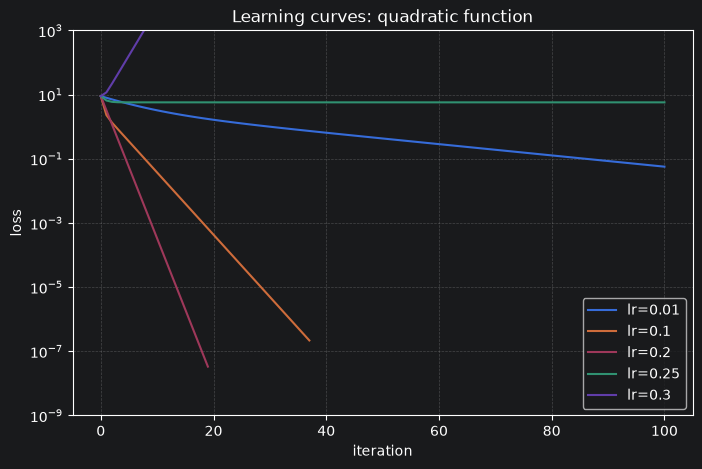

In [33]:
plt.figure(figsize=(8, 5))
for label, history in results_quadratic.items():
    plt.plot(history['loss'], label=label)
plt.yscale('log')
plt.ylim(1e-9, 1e3)
plt.xlabel('iteration')
plt.ylabel('loss')
plt.title('Learning curves: quadratic function')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.3)
plt.show()

**Ваш ответ:**
- **Остановка по `tol`.** Остановились $\eta = 0.1$ (37 итераций, loss $2.2\cdot 10^{-7}$) и $\eta = 0.2$ (19 итераций, loss $3.3\cdot 10^{-8}$). При $\eta = 0.01$ спуск не успел: множитель по $x$ равен $1 - 2\cdot 0.01 = 0.98$, и за 100 итераций $0.98^{100} \approx 0.13$; точка осталась в $(-0.239,\ 0.0003)$, loss 0.057, норма градиента 0.48 $>$ `tol`$= 10^{-3}$.
- **Формулы.** $x_{k+1} = (1 - 2\eta)\,x_k$, $y_{k+1} = (1 - 8\eta)\,y_k$. Координата стремится к нулю, когда $|1 - c\eta| < 1$: для $y$ это $0 < \eta < 0.25$, для $x$ — $0 < \eta < 1$.
- **$\eta = 0.2$.** Множитель по $y$ равен $1 - 1.6 = -0.6$: знак меняется на каждом шаге, поэтому траектория зигзагом перескакивает через $y = 0$. Множитель по $x$ равен $1 - 0.4 = +0.6$: знак сохраняется, $x$ приближается к нулю монотонно, зигзага по $x$ нет.
- **$\eta = 0.25$.** Множитель по $y$ равен $1 - 2 = -1$, поэтому $|y|$ не меняется: $y$ прыгает между $1.2$ и $-1.2$ (цикл из двух точек), а $x \to 0$ (около $10^{-30}$). Loss стартует с $9$ и быстро выходит на константу $4\cdot 1.2^2 = 5.76$: вклад $x^2$ затухает, а $4y^2$ не меняется. Норма градиента по `history['grad_norm']` идёт $10.25,\ 9.77,\ 9.64,\ \dots$ и стремится к $8\cdot 1.2 = 9.6$, а не к нулю. Это не сходимость: все 100 итераций выполнены, `tol` не сработал, до минимума $(0, 0)$ точка не дошла.
- **$\eta = 0.3$.** Множитель по $y$ равен $1 - 2.4 = -1.4$: $|y|$ растёт в 1.4 раза за шаг, спуск расходится; за 100 итераций $|y| \approx 5\cdot 10^{14}$, loss $\approx 9.7\cdot 10^{29}$.
- **Что ограничивает шаг и скорость.** Шаг должен удовлетворять условию для всех координат сразу, то есть $\eta < 0.25$; его задаёт самое крутое направление $y$ (кривизна 8: $\eta < 2/8$). Скорость определяется худшим множителем $\max(|1 - 2\eta|, |1 - 8\eta|)$. При малых $\eta$ это $1 - 2\eta$ — самое пологое направление $x$ (кривизна 2), множитель близок к 1 и спуск медленный, как при $\eta = 0.01$. Лучший шаг $\eta = 0.2$ уравнивает оба множителя по модулю ($0.6$), поэтому он самый быстрый — 19 итераций.

### Задание 2.4. Шаг обучения на функции Розенброка (0.5 балла)

Теперь невыпуклая функция Розенброка ($a = 1$, $b = 100$, минимум в точке $(1, 1)$).

1. **(0.15)** Для каждого шага из `learning_rates_rosen` запустите спуск из точки `(-1.5, 2.0)` с `n_iterations=10000` и `tol=1e-3`. Истории сохраните в словарь `results_rosen`, выведите число итераций, финальное значение функции и финальную точку. Если увидите предупреждение `RuntimeWarning: overflow` — это не ошибка в коде, а признак того, что спуск разошёлся.
2. Запустите готовую ячейку с графиками.
3. **(0.1)** Постройте кривые обучения для всех шагов (логарифмическая шкала по $y$). Расходящийся запуск улетает к огромным значениям и растягивает ось — ограничьте её, например `plt.ylim(1e-7, 1e4)`, чтобы остальные кривые было видно.
4. **(0.25)** Ответьте на вопросы:
   - При каком $\eta$ спуск остановился по `tol` около минимума? Сколько итераций понадобилось?
   - Как выглядит траектория: как спуск ведёт себя в начале и как — на дне «оврага»? Почему по дну оврага он движется так медленно?
   - Что произошло при $\eta = 0.0025$?
   - В задании 2.3 хорошо работал шаг 0.1. Почему здесь нельзя взять такой же? Подсказка: сравните норму градиента двух функций в стартовых точках (первое значение в `history['grad_norm']`).

In [34]:
learning_rates_rosen = [0.0001, 0.0005, 0.001, 0.0018, 0.0025]
start_rosen = np.array([-1.5, 2.0])
results_rosen = {}

for learning_rate in learning_rates_rosen:
    gd = GradientDescent(learning_rate=learning_rate, n_iterations=10000, tol=1e-3)
    with np.errstate(over='ignore', invalid='ignore'):
        final = gd.fit(rosenbrock_loss, rosenbrock_grad, start_rosen)
    results_rosen[f'lr={learning_rate}'] = gd.history
    iterations = len(gd.history['loss']) - 1
    print(f'lr={learning_rate}: iterations={iterations}, '
          f'final loss={gd.history["loss"][-1]:.6g}, final point={final}')

lr=0.0001: iterations=10000, final loss=2.78176, final point=[-0.66593918  0.45147674]
lr=0.0005: iterations=10000, final loss=0.00654525, final point=[0.91916852 0.84453129]
lr=0.001: iterations=10000, final loss=9.61559e-05, final point=[0.99020202 0.98046061]
lr=0.0018: iterations=8229, final loss=1.24913e-06, final point=[0.99888325 0.99776327]
lr=0.0025: iterations=10000, final loss=nan, final point=[nan nan]


In [35]:
x_range = np.linspace(-2, 2, 150)
y_range = np.linspace(-1, 3, 150)

plot_gd_2d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска', min_point=(1, 1))
plot_gd_3d(rosenbrock_loss, results_rosen, x_range, y_range,
           title='Функция Розенброка: траектории спуска (3D)', min_point=(1, 1))

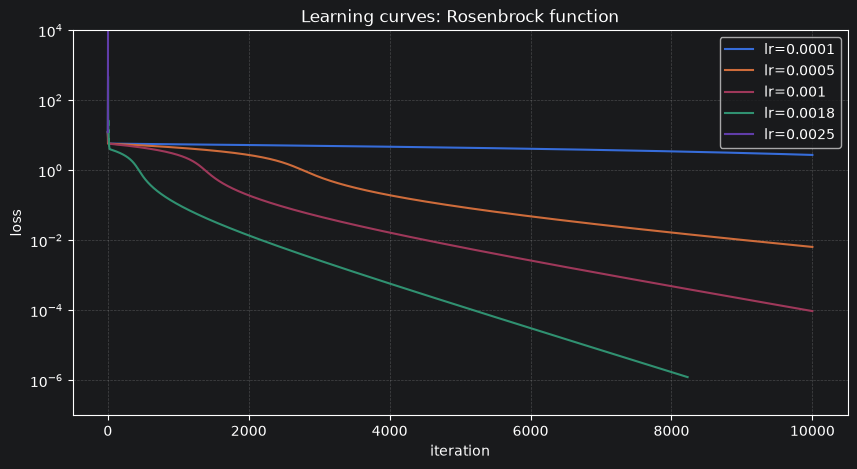

In [36]:
plt.figure(figsize=(10, 5))
for label, history in results_rosen.items():
    plt.plot(history['loss'], label=label)
plt.yscale('log')
plt.ylim(1e-7, 1e4)
plt.xlabel('iteration')
plt.ylabel('loss')
plt.title('Learning curves: Rosenbrock function')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.3)
plt.show()

**Ваш ответ:**
- **Остановка по `tol`.** Около минимума остановился только $\eta = 0.0018$: 8229 итераций, loss $1.25\cdot 10^{-6}$, точка $(0.9989,\ 0.9978)$. При $\eta = 0.001$ за 10 000 итераций точка $(0.990,\ 0.980)$ ещё не дошла (loss $9.6\cdot 10^{-5}$), при $0.0005$ loss равен 0.0065, при $0.0001$ — 2.78.
- **Траектория.** В начале спуск быстро падает в «овраг» (крутой склон, большой градиент), затем очень медленно ползёт по его изогнутому дну $y = x^2$. На дне градиент мал, а поперёк оврага кривизна огромна: в точке $(1, 1)$ собственные числа гессиана равны примерно $1001.6$ (поперёк) и $0.4$ (вдоль). Чтобы устойчиво остановиться у минимума, шаг должен быть меньше $2/1001.6 \approx 0.002$ (его ограничивает крутое направление), а за такой шаг вдоль дна множитель $1 - 0.4\eta$ почти равен 1 (при $\eta = 0.0018$ это $\approx 1 - 7\cdot 10^{-4}$): нужны тысячи итераций.
- **$\eta = 0.0025$.** Спуск расходится: loss растёт $12.5 \to 83 \to 729 \to 8934 \to 7.8\cdot 10^{7} \to 4.8\cdot 10^{19} \to \dots$ и на 8-й итерации становится `inf`; точки при этом $(-1.5,\ 2) \to (-1.11,\ 2.13) \to (-2.09,\ 1.68) \to (3.53,\ 3.02) \to (-29.8,\ 7.7) \to (26\,334,\ 449)$. Дальше переполняются и координаты, все значения становятся `nan`, критерий `tol` не срабатывает, поэтому в выводе все 10 000 итераций и `final loss=nan`. На крутом склоне вдали от дна шаг перелетает через овраг, попадает в точку с большим $|x|$, где кривизна ещё больше (порядка $1200x^2$), и следующий перелёт получается ещё больше: ошибка растёт лавинообразно. С $\eta = 0.0018$ такого не происходит, хотя первые шаги тоже перелетают (loss $12.5 \to 40.8 \to 140.3$), а затем траектория возвращается в овраг. Кроме того, даже если бы спуск дошёл до минимума, шаг $\eta = 0.0025$ был бы больше $2/\lambda_{max}(1,1) \approx 0.002$ и там не смог бы устойчиво остановиться.
- **Почему нельзя $\eta = 0.1$.** Норма градиента в стартовой точке Розенброка $(-1.5,\ 2)$ равна 162.9, у квадратичной функции в $(-1.8,\ 1.2)$ — 10.25 (в 16 раз меньше). Первый шаг при $\eta = 0.1$ имел бы длину $0.1\cdot 162.9 \approx 16$ — это далеко за пределы области. Кривизна здесь тоже на два порядка больше (максимальное собственное число около 1000 против 8 у квадратичной функции), поэтому допустимые шаги порядка $10^{-3}$, а не $10^{-1}$.

### Задание 2.5. Расписание шага (0.75 балла)

Мы видели дилемму: большой шаг быстро двигает спуск вперёд, но не даёт «успокоиться» у минимума и может разойтись; маленький шаг устойчив, но медленный. Отсюда идея — **менять шаг по ходу обучения** (learning rate schedule): в начале шагать крупно, потом всё мельче: $\eta_k = \eta(k)$.

Популярные расписания:

- **step decay** — уменьшать шаг в $\gamma$ раз каждые несколько итераций: $\eta_k = \eta_0 \cdot \gamma^{\lfloor k / s \rfloor}$;
- **exponential decay** — $\eta_k = \eta_0 \cdot \gamma^k$, $0 < \gamma < 1$;
- **inverse time decay** — $\eta_k = \dfrac{\eta_0}{1 + \text{decay} \cdot k}$. Оно уже реализовано в вашем классе.

Сравним постоянный шаг и inverse time decay на функции Розенброка из точки `(-1.2, 1.0)`, `n_iterations=3000`, без `tol`.

1. **(0.25)** Запустите спуск с постоянным шагом $\eta = 0.003$. Затем — с тем же $\eta_0 = 0.003$ и расписанием: подберите `decay` так, чтобы финальное значение функции было **меньше 0.002**. Попробуйте несколько значений `decay` от `1e-4` до `1e-2` и выведите финальные значения для каждого. Для сравнения запустите ещё и лучший постоянный шаг из 2.4 ($\eta = 0.0018$).
2. **(0.2)** Постройте траектории готовыми функциями (постоянный 0.003, лучший `decay`, постоянный 0.0018) и два графика: кривые обучения (логарифмическая шкала) и шаг обучения $\eta_k$ по итерациям (`history['lr']`).
3. **(0.3)** Ответьте на вопросы:
   - Почему спуск с постоянным шагом 0.003 застрял? Посмотрите на траекторию вблизи дна оврага и на последние точки `history['params'][-4:]`. Дно оврага — кривая $y = x^2$.
   - Как расписание помогло с тем же стартовым шагом?
   - Что получается при слишком большом `decay`, например `1e-2`? А при слишком маленьком?
   - Сравните расписание с постоянным шагом 0.0018. Что лучше и почему?

In [37]:
start_schedule = np.array([-1.2, 1.0])
schedule_results = {}

constant_003 = GradientDescent(learning_rate=0.003, n_iterations=3000)
constant_003.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
schedule_results['eta=0.003'] = constant_003.history

for decay in [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]:
    gd = GradientDescent(learning_rate=0.003, n_iterations=3000, decay=decay)
    gd.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
    schedule_results[f'decay={decay}'] = gd.history
    print(f'decay={decay}: final loss={gd.history["loss"][-1]:.6g}')

best_schedule_label, _ = min(
    ((label, history['loss'][-1]) for label, history in schedule_results.items()
     if label.startswith('decay=')),
    key=lambda item: item[1]
)

constant_0018 = GradientDescent(learning_rate=0.0018, n_iterations=3000)
constant_0018.fit(rosenbrock_loss, rosenbrock_grad, start_schedule)
schedule_results['eta=0.0018'] = constant_0018.history

print('Постоянный шаг 0.003, последние точки:')
print(np.array(constant_003.history['params'][-4:]))
print('Постоянный шаг 0.003, final loss:', constant_003.history['loss'][-1])
print('Лучший постоянный шаг 0.0018, final loss:', constant_0018.history['loss'][-1])

decay=0.0001: final loss=0.0838995
decay=0.0005: final loss=0.00161488
decay=0.001: final loss=0.00521185
decay=0.005: final loss=0.0674268
decay=0.01: final loss=0.172087
Постоянный шаг 0.003, последние точки:
[[0.78595422 0.56697099]
 [0.73937101 0.59742281]
 [0.78596543 0.56697082]
 [0.73936469 0.59743332]]
Постоянный шаг 0.003, final loss: 0.32572225691609175
Лучший постоянный шаг 0.0018, final loss: 0.0025664183142612147


In [38]:
plot_gd_2d(
    rosenbrock_loss,
    {
        'eta=0.003': schedule_results['eta=0.003'],
        best_schedule_label: schedule_results[best_schedule_label],
        'eta=0.0018': schedule_results['eta=0.0018']
    },
    x_range=np.linspace(-2, 2, 150),
    y_range=np.linspace(-1, 3, 150),
    title='Функция Розенброка: постоянный шаг и расписание',
    min_point=(1, 1)
)
plot_gd_3d(
    rosenbrock_loss,
    {
        'eta=0.003': schedule_results['eta=0.003'],
        best_schedule_label: schedule_results[best_schedule_label],
        'eta=0.0018': schedule_results['eta=0.0018']
    },
    x_range=np.linspace(-2, 2, 150),
    y_range=np.linspace(-1, 3, 150),
    title='Функция Розенброка: постоянный шаг и расписание (3D)',
    min_point=(1, 1)
)

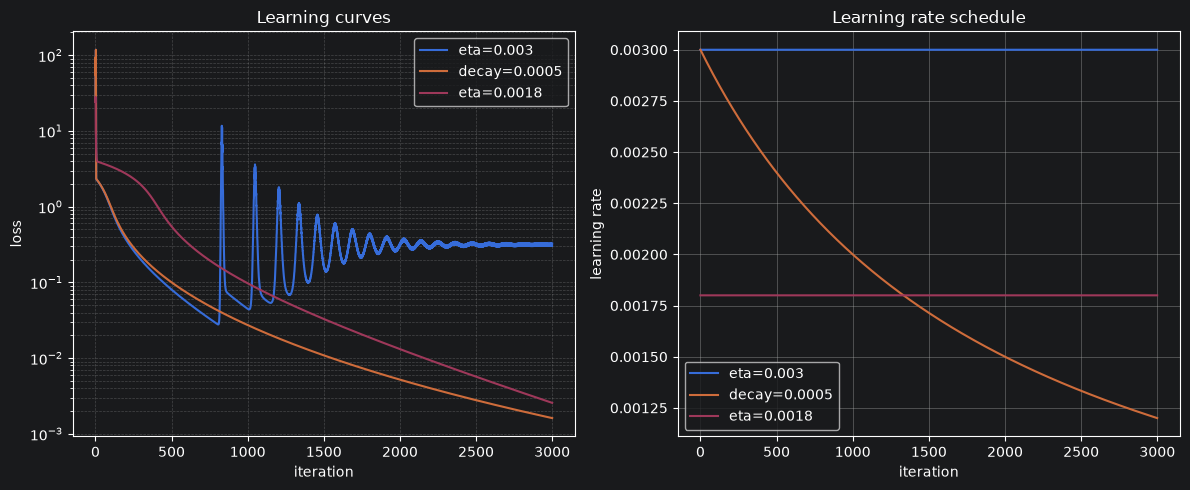

In [39]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
for label in ['eta=0.003', best_schedule_label, 'eta=0.0018']:
    plt.plot(schedule_results[label]['loss'], label=label)
plt.yscale('log')
plt.xlabel('iteration')
plt.ylabel('loss')
plt.title('Learning curves')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.3)

plt.subplot(1, 2, 2)
for label in ['eta=0.003', best_schedule_label, 'eta=0.0018']:
    plt.plot(schedule_results[label]['lr'], label=label)
plt.xlabel('iteration')
plt.ylabel('learning rate')
plt.title('Learning rate schedule')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Ваш ответ:**
- **Почему застрял $\eta = 0.003$.** Финальный loss 0.326. Последние точки истории: $(0.7860,\ 0.5670)$, $(0.7394,\ 0.5974)$, $(0.7860,\ 0.5670)$, $(0.7394,\ 0.5974)$ — периодическое колебание из двух точек. Дно оврага при $x = 0.786$ имеет $y = x^2 = 0.618$, а точка лежит ниже ($0.567$); при $x = 0.739$ дно $0.547$, а точка выше ($0.597$). Спуск перепрыгивает с одной стороны дна на другую и не продвигается вдоль него. При этом до примерно 800-й итерации $\eta = 0.003$ шёл вдоль дна лучше всех (на 800-й итерации точка $(0.832,\ 0.692)$, loss $0.028$ против $0.043$ у лучшего расписания и $0.167$ у $\eta = 0.0018$). Но по мере продвижения к $(1, 1)$ кривизна поперёк оврага растёт: порог устойчивости $2/\lambda_{max}$ около $0.0030$ при $x \approx 0.76$ и около $0.0020$ в $(1, 1)$. При $x \approx 0.8$ он стал меньше $0.003$, около 820-й итерации спуск потерял устойчивость (loss подскочил до $\approx 11.7$), его отбросило назад к $x \approx 0.74$–$0.79$, и он застрял в этом цикле из двух точек (финальный loss $0.326$).
- **Что дало расписание.** При $\eta_k = 0.003/(1 + 0.0005k)$ в начале шаг тот же, что у постоянного $0.003$ (быстро спуститься в овраг), а затем $\eta_k$ падает (до $0.0012$ к концу) ниже порога устойчивости, колебания затухают, и спуск идёт вдоль дна. Финальный loss $0.00161$ (лучший из перебранных, меньше $0.002$) против $0.326$.
- **Слишком большой `decay`.** При $10^{-2}$ шаг быстро падает: к 200-й итерации до $0.001$, к концу примерно до $10^{-4}$. Спуск почти замирает: loss $0.172$. **Слишком маленький.** При $10^{-4}$ шаг почти не меняется ($0.0023$ к концу), и спуск тоже заканчивает в цикле из двух точек $(0.924,\ 0.827) \leftrightarrow (0.902,\ 0.840)$, но дальше по оврагу, где локальный порог $2/\lambda_{max} \approx 0.0023$ совпадает с шагом: loss $0.0839$ (в 4 раза меньше, чем у постоянного $0.003$, но всё ещё плохо). Для остальных значений: $5\cdot 10^{-4}$ — $0.00161$ (лучший), $10^{-3}$ — $0.00521$, $5\cdot 10^{-3}$ — $0.0674$.
- **Расписание против постоянного $0.0018$.** Расписание лучше: $0.00161$ против $0.00257$. Шаг $0.0018$ устойчив с самого начала, но мал, и спуск вдоль оврага идёт медленно (loss на 1000-й итерации $0.097$ против $0.027$ у расписания). Расписание начинает с большого шага и быстрее проходит овраг, а к концу уменьшает шаг и успокаивается.

### Задание 2.6. Градиентный спуск для линейной регрессии (1 балл)

Вернёмся к машинам и обучим линейную регрессию из 1.4 своим `GradientDescent`.

Добавим к признакам столбец из единиц — тогда свободный член (intercept) станет обычным весом $w_0$. Для матрицы признаков $X$ размера $n \times (d+1)$ и вектора весов $w$:
$$L(w) = \frac{1}{n}\,\|Xw - y\|^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i^\top w - y_i)^2, \qquad \nabla L(w) = \frac{2}{n}\,X^\top (Xw - y).$$

1. **(0.25)** Реализуйте `mse_loss(w, X, y)` и `mse_grad(w, X, y)` по этим формулам — без циклов, через матричные операции NumPy (`@` — матричное умножение, `.T` — транспонирование).
2. **(0.25)** Запустите спуск из $w_0 = 0$ (`np.zeros(X_gd.shape[1])`) на `X_gd`, `y_gd` из ячейки ниже для шагов `[0.01, 0.1, 0.3, 0.5]` с `n_iterations=1000` и `tol=1`. Класс ожидает функции от одного аргумента `w`, поэтому передавайте `lambda w: mse_loss(w, X_gd, y_gd)` (и так же для градиента). Выведите для каждого шага число итераций и финальный loss, постройте кривые обучения (логарифмическая шкала; у расходящегося запуска в истории окажется `inf`, поэтому задайте пределы оси, например `plt.ylim(1e11, 1e13)`). При каком шаге спуск разошёлся?
3. **(0.25)** Сравните веса лучшего запуска с `lin_reg_scaled` из 1.4 (`intercept_` и `coef_`), сведите их в таблицу. Посчитайте $R^2$ своей модели на test: не забудьте добавить столбец единиц к `X_test_scaled`.
4. **(0.25)** Повторите спуск на **нестандартизированных** признаках: `X_train` из 1.1 со столбцом единиц, шаг `1e-10`, 1000 итераций (с шагом побольше спуск расходится, можете проверить). Сравните финальный loss с результатом на стандартизированных признаках. Почему без стандартизации спуск не справляется? Свяжите ответ с заданием 2.3.

In [40]:
# матрица признаков со столбцом единиц (для intercept) и таргет в виде массивов NumPy
X_gd = np.hstack([np.ones((X_train_scaled.shape[0], 1)), X_train_scaled])
y_gd = y_train.to_numpy()
print(X_gd.shape, y_gd.shape)

(5843, 7) (5843,)


In [41]:
def mse_loss(w, X, y):
    return np.mean((X @ w - y) ** 2)


def mse_grad(w, X, y):
    return 2 / len(y) * X.T @ (X @ w - y)

In [42]:
# Проверка. Для квадратичной функции центральная разность точна при любом h, поэтому берём h=1
w_check = np.arange(X_gd.shape[1], dtype=float)
assert np.isclose(mse_loss(w_check, X_gd, y_gd), mean_squared_error(y_gd, X_gd @ w_check)), 'mse_loss считает неверно'
assert np.allclose(mse_grad(w_check, X_gd, y_gd),
                   numerical_grad(lambda w: mse_loss(w, X_gd, y_gd), w_check, h=1.0), rtol=1e-6), 'mse_grad считает неверно'
print('mse_loss и mse_grad посчитаны верно.')

mse_loss и mse_grad посчитаны верно.


In [43]:
learning_rates_linreg = [0.01, 0.1, 0.3, 0.5]
results_linreg = {}

for learning_rate in learning_rates_linreg:
    gd = GradientDescent(learning_rate=learning_rate, n_iterations=1000, tol=1)
    with np.errstate(over='ignore', invalid='ignore'):
        weights = gd.fit(lambda w: mse_loss(w, X_gd, y_gd),
                         lambda w: mse_grad(w, X_gd, y_gd),
                         np.zeros(X_gd.shape[1]))
    results_linreg[f'lr={learning_rate}'] = gd.history
    iterations = len(gd.history['loss']) - 1
    print(f'lr={learning_rate}: iterations={iterations}, final loss={gd.history["loss"][-1]:.6g}')

lr=0.01: iterations=1000, final loss=1.16854e+11
lr=0.1: iterations=318, final loss=1.16852e+11
lr=0.3: iterations=103, final loss=1.16852e+11
lr=0.5: iterations=1000, final loss=inf


Лучший запуск: lr=0.3
   parameter  gradient_descent  LinearRegression
0  intercept     522967.813110     522967.813110
1       year     152898.696383     152898.498205
2  km_driven     -43954.029712     -43953.853566
3    mileage      28791.922338      28791.816950
4     engine      61373.292038      61371.072884
5  max_power     322548.708506     322550.136077
6      seats     -23442.273501     -23441.054866
R2 на train: 0.592137191583419  MSE на train: 116851699647.94943
R2 на test: 0.5939744451083098  MSE на test: 233395083270.68826


/Users/ilyatikhonov/Documents/projects/ALL_ML/SE_ML/.venv/lib/python3.14/site-packages/matplotlib/scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


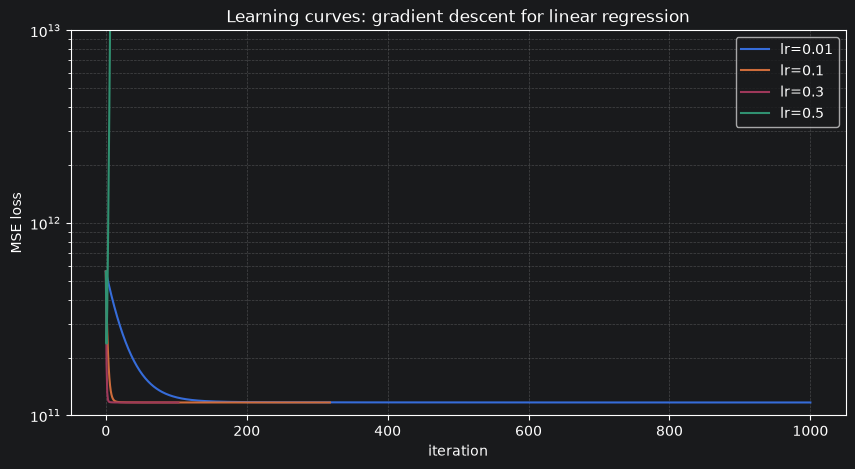

In [44]:
valid_results = {
    label: history for label, history in results_linreg.items()
    if np.isfinite(history['loss'][-1])
}
best_linreg_label = min(valid_results, key=lambda label: valid_results[label]['loss'][-1])
w_gd = np.array(valid_results[best_linreg_label]['params'][-1])

comparison = pd.DataFrame({
    'parameter': ['intercept'] + num_features,
    'gradient_descent': w_gd,
    'LinearRegression': np.r_[lin_reg_scaled.intercept_, lin_reg_scaled.coef_]
})
print('Лучший запуск:', best_linreg_label)
print(comparison)

X_test_gd = np.hstack([np.ones((X_test_scaled.shape[0], 1)), X_test_scaled])
print('R2 на train:', r2_score(y_train, X_gd @ w_gd), ' MSE на train:', mean_squared_error(y_train, X_gd @ w_gd))
print('R2 на test:', r2_score(y_test, X_test_gd @ w_gd), ' MSE на test:', mean_squared_error(y_test, X_test_gd @ w_gd))

plt.figure(figsize=(10, 5))
for label, history in results_linreg.items():
    plt.plot(history['loss'], label=label)
plt.yscale('log')
plt.ylim(1e11, 1e13)
plt.xlabel('iteration')
plt.ylabel('MSE loss')
plt.title('Learning curves: gradient descent for linear regression')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.3)
plt.show()

In [45]:
X_train_raw_gd = np.hstack([np.ones((X_train.shape[0], 1)), X_train.to_numpy()])
gd_raw = GradientDescent(learning_rate=1e-10, n_iterations=1000, tol=1)
w_raw = gd_raw.fit(lambda w: mse_loss(w, X_train_raw_gd, y_gd),
                   lambda w: mse_grad(w, X_train_raw_gd, y_gd),
                   np.zeros(X_train_raw_gd.shape[1]))
print('Loss без стандартизации:', gd_raw.history['loss'][-1])
print('Лучший loss со стандартизацией:', valid_results[best_linreg_label]['loss'][-1])
# собственные числа гессиана MSE: (2/n) X^T X
eig_scaled = np.linalg.eigvalsh(2 / len(y_gd) * X_gd.T @ X_gd)
eig_raw = np.linalg.eigvalsh(2 / len(y_gd) * X_train_raw_gd.T @ X_train_raw_gd)
print(f'Со стандартизацией: lambda_max = {eig_scaled[-1]:.4g}, lambda_min = {eig_scaled[0]:.4g}, '
      f'2/lambda_max = {2 / eig_scaled[-1]:.4g}, lambda_max/lambda_min = {eig_scaled[-1] / eig_scaled[0]:.4g}')
print(f'Без стандартизации: lambda_max = {eig_raw[-1]:.4g}, lambda_min = {eig_raw[0]:.4g}, '
      f'2/lambda_max = {2 / eig_raw[-1]:.4g}, lambda_max/lambda_min = {eig_raw[-1] / eig_raw[0]:.4g}')

Loss без стандартизации: 317025976603.0677
Лучший loss со стандартизацией: 116851699647.94943
Со стандартизацией: lambda_max = 5.187, lambda_min = 0.3173, 2/lambda_max = 0.3856, lambda_max/lambda_min = 16.35
Без стандартизации: lambda_max = 1.814e+10, lambda_min = 5.445e-06, 2/lambda_max = 1.102e-10, lambda_max/lambda_min = 3.332e+15


**Ваш ответ:**
- **Какой шаг разошёлся.** $\eta = 0.5$: после первого шага loss растёт, на 727-й итерации переполняется до `inf` и дальше так и остаётся; `tol` не срабатывает, поэтому выполнены все 1000 итераций. Остальные: $\eta = 0.01$ — 1000 итераций (`tol` не достигнут), loss $1.16854\cdot 10^{11}$; $\eta = 0.1$ — 318 итераций; $\eta = 0.3$ — 103 итерации (лучший), loss $1.16852\cdot 10^{11}$. Порог устойчивости $2/\lambda_{max}$, где $\lambda_{max} = 5.19$ — наибольшее собственное число гессиана $\frac{2}{n}X^\top X$: $2/5.19 \approx 0.386$, поэтому $0.3$ допустим, а $0.5$ нет.
- **Сравнение с `LinearRegression`.** Веса лучшего запуска ($\eta = 0.3$) совпадают с `lin_reg_scaled` из 1.4 примерно до 4–5 значащих цифр: intercept $522\,967.8$ в обоих случаях, `max_power` $322\,548.7$ против $322\,550.1$, `year` $152\,898.7$ против $152\,898.5$. $R^2$ на test равен $0.59397$, как $0.5940$ в 1.4 (train $0.5921$).
- **Без стандартизации.** При $\eta = 10^{-10}$ и 1000 итерациях loss равен $3.17\cdot 10^{11}$ против $1.169\cdot 10^{11}$ со стандартизацией (в 2.7 раза больше): спуск не дошёл до минимума. Как в 2.3, допустимый шаг задаётся самым крутым направлением, а скорость — самым пологим. Без стандартизации масштабы признаков сильно различаются (`km_driven` порядка $10^5$, `seats` порядка 5), собственные числа гессиана лежат в диапазоне от $5.4\cdot 10^{-6}$ до $1.8\cdot 10^{10}$ (число обусловленности $3.3\cdot 10^{15}$; со стандартизацией — от 0.32 до 5.19, число обусловленности 16). Шаг обязан быть меньше $2/\lambda_{max} \approx 1.1\cdot 10^{-10}$, и при таком шаге по направлениям малой кривизны (свободный член, `seats`, `mileage` и другие признаки малого масштаба) множитель $1 - \eta\lambda$ почти равен 1, то есть за 1000 шагов прогресса практически нет. Увеличить шаг нельзя: спуск разойдётся из-за `km_driven`.

### Задание 2.7. Стохастический градиентный спуск (0.5 балла)

В стохастическом (mini-batch) градиентном спуске (SGD) градиент на каждом шаге считаем не по всей выборке, а по небольшому случайному подмножеству объектов — **батчу** (batch). Шаг становится намного дешевле, но градиент — шумным.

Нашему классу можно просто передать другую функцию градиента. Loss при этом по-прежнему считается по всей выборке, так кривые обучения удобно сравнивать.

1. **(0.2)** Допишите `mse_grad_batch(w, batch_size)`: выберите `batch_size` случайных номеров объектов без повторов (`rng.choice(n, size=batch_size, replace=False)`) и верните градиент MSE только по этим объектам (используйте `mse_grad`).
2. **(0.15)** Обучите SGD на `X_gd`, `y_gd` с `batch_size` 1, 32 и 256: шаг 0.01, 1000 итераций, `tol=None`. Постройте кривые обучения вместе с полным GD с тем же шагом.
3. **(0.15)** Ответьте: как размер батча влияет на вид кривой и на финальный loss? Почему для SGD не годится критерий остановки по норме градиента?

batch=1: final loss=3.35809e+11
batch=32: final loss=1.17144e+11
batch=256: final loss=1.16962e+11
Норма полного градиента в w_gd: 0.927
batch=1: средняя норма градиента по батчу в w_gd = 9.24e+05
batch=32: средняя норма градиента по батчу в w_gd = 4.29e+05
batch=256: средняя норма градиента по батчу в w_gd = 2.11e+05


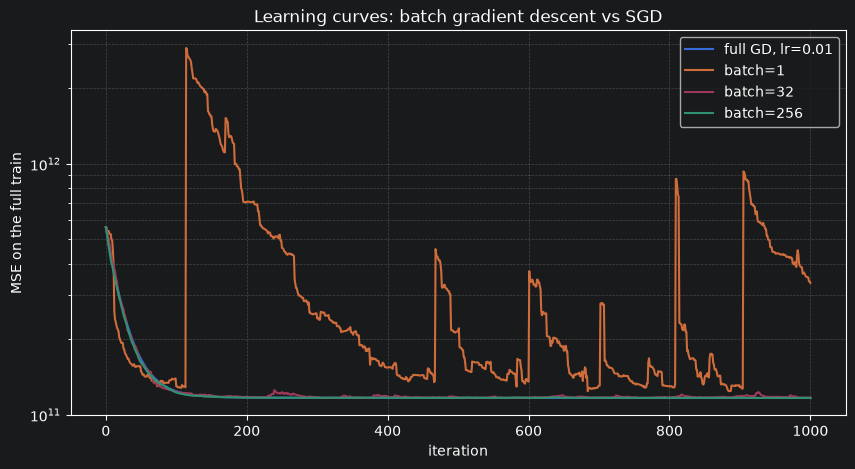

In [46]:
rng = np.random.default_rng(42)


def mse_grad_batch(w, batch_size):
    idx = rng.choice(len(y_gd), size=batch_size, replace=False)
    return mse_grad(w, X_gd[idx], y_gd[idx])


results_sgd = {'full GD, lr=0.01': results_linreg['lr=0.01']}

for batch_size in [1, 32, 256]:
    gd = GradientDescent(learning_rate=0.01, n_iterations=1000, tol=None)
    gd.fit(lambda w: mse_loss(w, X_gd, y_gd),
           lambda w: mse_grad_batch(w, batch_size),
           np.zeros(X_gd.shape[1]))
    results_sgd[f'batch={batch_size}'] = gd.history
    print(f'batch={batch_size}: final loss={gd.history["loss"][-1]:.6g}')

print(f'Норма полного градиента в w_gd: {np.linalg.norm(mse_grad(w_gd, X_gd, y_gd)):.3g}')
for batch_size in [1, 32, 256]:
    batch_norms = [np.linalg.norm(mse_grad_batch(w_gd, batch_size)) for _ in range(300)]
    print(f'batch={batch_size}: средняя норма градиента по батчу в w_gd = {np.mean(batch_norms):.3g}')

plt.figure(figsize=(10, 5))
for label, history in results_sgd.items():
    plt.plot(history['loss'], label=label)
plt.yscale('log')
plt.xlabel('iteration')
plt.ylabel('MSE on the full train')
plt.title('Learning curves: batch gradient descent vs SGD')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.3)
plt.show()

**Ваш ответ:**
- **Влияние размера батча.** Финальный loss на всём train: полный GD $1.16854\cdot 10^{11}$, `batch=256` $1.1696\cdot 10^{11}$, `batch=32` $1.1714\cdot 10^{11}$, `batch=1` $3.358\cdot 10^{11}$ (оптимум около $1.1685\cdot 10^{11}$). Чем меньше батч, тем более шумная кривая и тем выше финальный loss: при постоянном шаге SGD не сходится в точку, а колеблется вокруг минимума, и размах колебаний тем больше, чем шумнее градиент. При `batch=1` loss скачет и в конце почти втрое выше оптимума, `batch=256` почти совпадает с полным GD, `batch=32` близок к нему. Взамен каждый шаг SGD дешевле.
- **Критерий по норме градиента.** Градиент по батчу — шумная оценка полного градиента. Даже в точке `w_gd`, где норма полного градиента меньше 1, средняя норма градиента по батчу равна около $9.2\cdot 10^{5}$ при `batch=1`, $4.3\cdot 10^{5}$ при `batch=32` и $2.1\cdot 10^{5}$ при `batch=256` (значения из вывода выше): отдельные объекты имеют ненулевые остатки (RMSE $\approx 3.4\cdot 10^{5}$ руб.), и их градиенты не гасят друг друга. Такая норма на много порядков больше `tol`, поэтому критерий никогда не сработает (или сработает случайно на удачном батче) и не говорит о близости к минимуму.

## Чек-лист перед сдачей

- [ ] Перезапустил ядро и выполнил все ячейки сверху вниз — ошибок нет.
- [ ] Все выводы и графики сохранены в ноутбуке.
- [ ] Ответил текстом на все вопросы.
- [ ] Если пользовался LLM или чужим кодом, указал это.